Image shape: (5, 5)
[[3 1 0 2 1]
 [2 0 1 3 0]
 [4 1 0 1 2]
 [1 3 2 0 1]
 [0 2 1 4 2]]


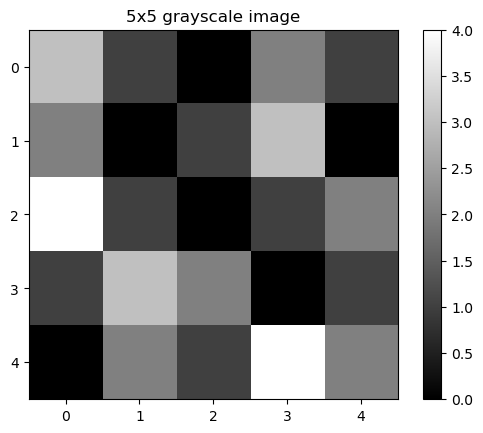

In [1]:
import numpy as np
import matplotlib.pyplot as plt

image = np.array([
    [3, 1, 0, 2, 1],
    [2, 0, 1, 3, 0],
    [4, 1, 0, 1, 2],
    [1, 3, 2, 0, 1],
    [0, 2, 1, 4, 2],
])

print('Image shape:', image.shape)
print(image)

plt.imshow(image, cmap='gray')
plt.title('5x5 grayscale image')
plt.colorbar()
plt.show()

In [2]:
kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1],
])

def convolve2d(img, k, stride=1):
    n, kh = img.shape[0], k.shape[0]
    out_size = (n - kh) // stride + 1
    out = np.zeros((out_size, out_size), dtype=int)
    for i in range(out_size):
        for j in range(out_size):
            region = img[i*stride:i*stride+kh, j*stride:j*stride+kh]
            out[i, j] = np.sum(region * k)
    return out

first_region = image[0:3, 0:3]
print('First 3x3 region:\n', first_region)
print('First value =', np.sum(first_region * kernel))

feature_map = convolve2d(image, kernel)
print('\nFeature map:\n', feature_map)

First 3x3 region:
 [[3 1 0]
 [2 0 1]
 [4 1 0]]
First value = 8

Feature map:
 [[ 8 -4 -2]
 [ 4  0  0]
 [ 2  1 -2]]


In [3]:
def relu(x):
    return np.maximum(0, x)

relu_out = relu(feature_map)
print('Before ReLU:\n', feature_map)
print('\nAfter ReLU:\n', relu_out)

Before ReLU:
 [[ 8 -4 -2]
 [ 4  0  0]
 [ 2  1 -2]]

After ReLU:
 [[8 0 0]
 [4 0 0]
 [2 1 0]]


In [4]:
def max_pool(x, size=2, stride=1):
    out_size = (x.shape[0] - size) // stride + 1
    out = np.zeros((out_size, out_size), dtype=x.dtype)
    for i in range(out_size):
        for j in range(out_size):
            window = x[i*stride:i*stride+size, j*stride:j*stride+size]
            out[i, j] = np.max(window)
    return out

print('First window:\n', relu_out[0:2, 0:2], '-> max =', np.max(relu_out[0:2, 0:2]))

pooled = max_pool(relu_out, size=2, stride=1)
print('\nPooled 2x2:\n', pooled)

First window:
 [[8 0]
 [4 0]] -> max = 8

Pooled 2x2:
 [[8 0]
 [4 1]]


In [5]:
flat = pooled.flatten()
print('Flattened vector:', flat)

classes = ['Cat', 'Dog', 'Bird']
weights = np.array([
    [0.3, 0.1, 0.2, 0.1],   # Cat
    [0.1, 0.2, 0.1, 0.3],   # Dog
    [0.0, 0.4, 0.1, 0.2],   # Bird
])

logits = weights @ flat
for c, z in zip(classes, logits):
    print(f'{c}: logit z = {z:.1f}')

Flattened vector: [8 0 4 1]
Cat: logit z = 3.3
Dog: logit z = 1.5
Bird: logit z = 0.6


Cat: 81.1%
Dog: 13.4%
Bird: 5.5%

Sum of probabilities: 1.0000000000000002
Prediction: Cat


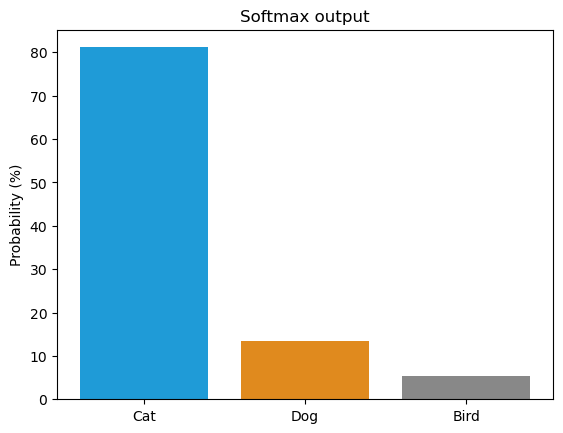

In [6]:
def softmax(z):
    e = np.exp(z - np.max(z))
    return e / e.sum()

probs = softmax(logits)
for c, p in zip(classes, probs):
    print(f'{c}: {p*100:.1f}%')

print('\nSum of probabilities:', probs.sum())
print('Prediction:', classes[np.argmax(probs)])

plt.bar(classes, probs * 100, color=['#1f9bd7', '#e08a1e', '#888888'])
plt.ylabel('Probability (%)')
plt.title('Softmax output')
plt.show()

{'Cat': np.float64(81.1), 'Dog': np.float64(13.4), 'Bird': np.float64(5.5)}


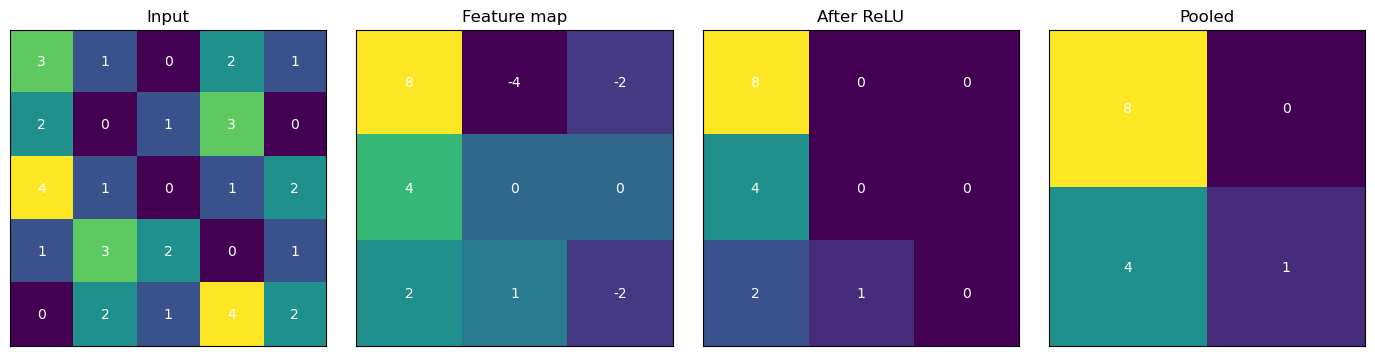

In [7]:
def cnn_forward(img):
    fm = convolve2d(img, kernel)
    r = relu(fm)
    p = max_pool(r, 2, 1)
    f = p.flatten()
    z = weights @ f
    return softmax(z)

result = cnn_forward(image)
print(dict(zip(classes, np.round(result * 100, 1))))

stages = [('Input', image), ('Feature map', feature_map),
          ('After ReLU', relu_out), ('Pooled', pooled)]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, (name, data) in zip(axes, stages):
    ax.imshow(data, cmap='viridis')
    ax.set_title(name)
    for (i, j), v in np.ndenumerate(data):
        ax.text(j, i, v, ha='center', va='center', color='white')
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()